# 04 · Tempo real e integração com o MVP

**Vídeo de teste:** `videos/rua.mp4` (10 s, 1920×1080, 30 fps) — gravado pela equipe em rua de São Paulo, só para
teste de tempo real (não faz parte do treino), placa desfocada, sem áudio.

**Tempo real** — no terminal, com janela:
```bash
python scripts/tempo_real.py --fonte 0                                    # webcam
python scripts/tempo_real.py --fonte videos/rua.mp4 --gravar resultados/demo.mp4
python scripts/tempo_real.py --fonte http://IP_DO_CELULAR:8080/video      # celular como câmera
```
Abaixo, o mesmo processamento sem janela, gravando o vídeo anotado `resultados/demo.mp4`.

In [1]:
import sys
!{sys.executable} ../scripts/tempo_real.py --fonte ../videos/rua.mp4 --gravar ../resultados/demo.mp4 --conf 0.35 --sem-janela

300 quadros processados · FPS médio de inferência (todos os quadros) = 91.3 (11.0 ms/quadro) · log em resultados/tempo_real_log.csv
Para o FPS do pipeline completo (ler + detectar + desenhar + gravar), use scripts/medir_fps.py.


## FPS medido em todos os quadros
`medir_fps.py` separa duas medidas: **inferência** (só o detector, como no `tempo_real.py`) e **pipeline completo**
(ler o quadro 1080p + detectar + desenhar + gravar o vídeo). O vídeo tem 30 fps: acima disso, é tempo real.

In [2]:
!{sys.executable} ../scripts/medir_fps.py --fonte ../videos/rua.mp4 --saida ../resultados/fps_video.json

{
  "video": "rua.mp4",
  "resolucao": "1920x1080",
  "fps_do_video": 30.0,
  "quadros": 300,
  "gpu": "NVIDIA GeForce RTX 5060 Ti",
  "conf": 0.35,
  "imgsz": 640,
  "inferencia_ms_media": 10.81,
  "inferencia_ms_p95": 12.97,
  "fps_inferencia": 92.5,
  "pipeline_ms_media": 26.18,
  "fps_pipeline": 38.2
}


## Quadros com buraco no vídeo (limiar 0,35)

In [3]:
import pandas as pd
log = pd.read_csv("../resultados/tempo_real_log.csv")
print(f"Quadros com pelo menos 1 detecção: {len(log)} de 300")
print("Caixas por quadro:", log.n_buracos.value_counts().sort_index().to_dict())
print("Severidade:", log.severidade.value_counts().to_dict())

Quadros com pelo menos 1 detecção: 221 de 300
Caixas por quadro: {1: 43, 2: 121, 3: 37, 4: 20}
Severidade: {'media': 154, 'alta': 35, 'baixa': 32}


## Quadros do vídeo anotado (usados no relatório)
(a) acerto: buraco na rua · (b) falso positivo: tampa de inspeção na calçada · (c) falso positivo: mancha na calçada ·
(d) falsos positivos na sarjeta com mato — com 4 caixas, a severidade vai para "alta". Causa provável dos falsos
positivos: o dataset de treino não tem imagens negativas (sem buraco).

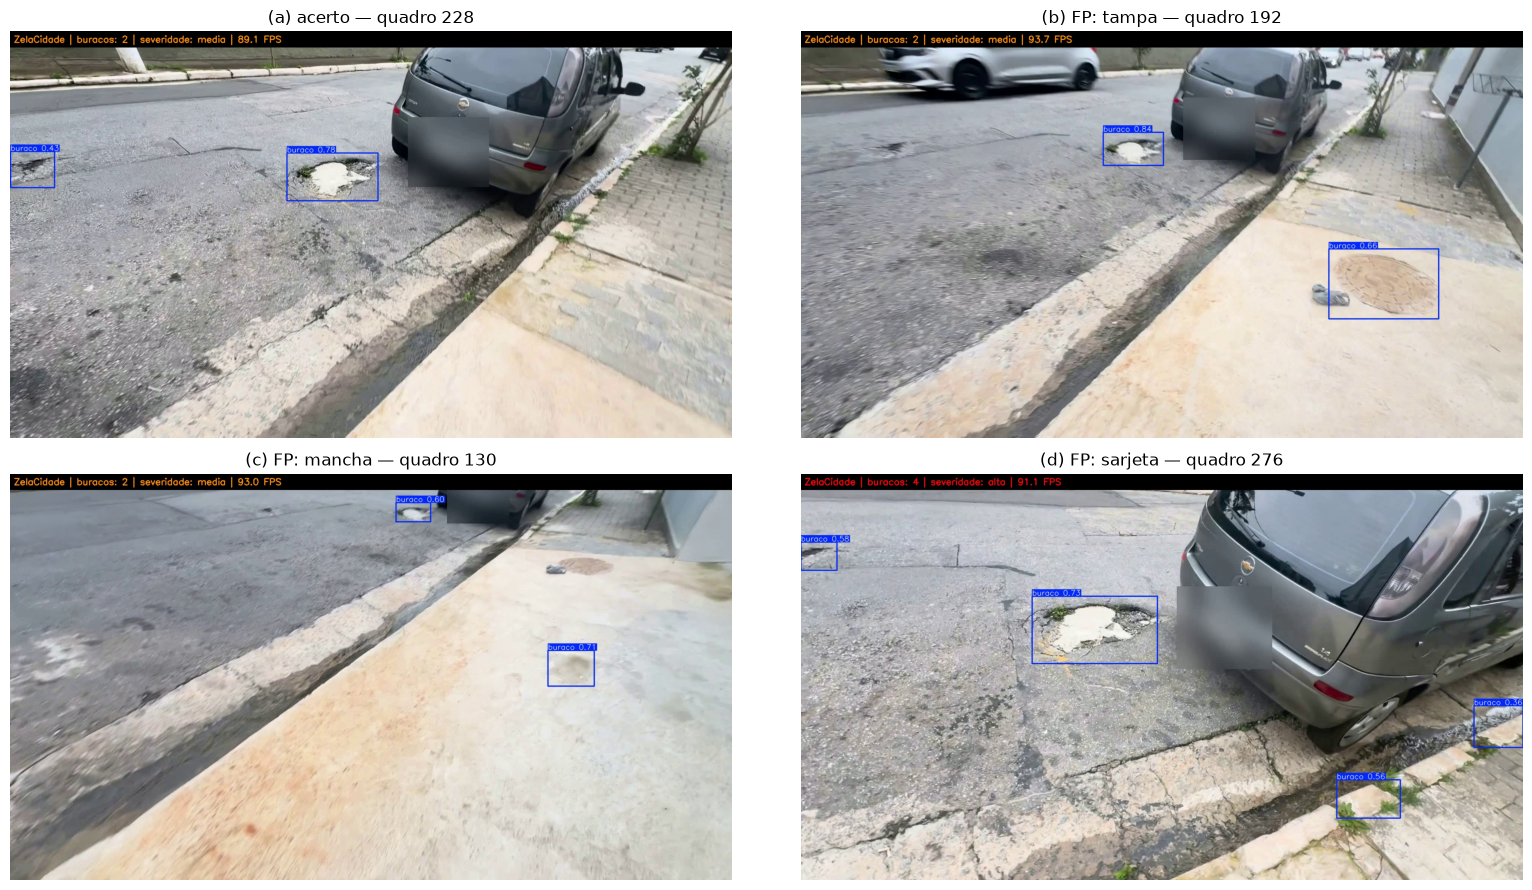

In [4]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
nomes = {228: "q228_acerto_buraco_na_rua", 192: "q192_acerto_e_FP_tampa_na_calcada",
         130: "q130_FP_mancha_na_calcada", 276: "q276_FP_sarjeta_com_mato_severidade_inflada"}
pasta = Path("../resultados/quadros_demo"); pasta.mkdir(exist_ok=True)
cap, i, quadros = cv2.VideoCapture("../resultados/demo.mp4"), 0, {}
while True:
    ok, f = cap.read()
    if not ok:
        break
    if i in nomes:
        cv2.imwrite(str(pasta / f"{nomes[i]}.jpg"), f, [cv2.IMWRITE_JPEG_QUALITY, 90]); quadros[i] = f
    i += 1
fig, axs = plt.subplots(2, 2, figsize=(16, 9))
for ax, (k, rot) in zip(axs.ravel(), [(228, "(a) acerto"), (192, "(b) FP: tampa"), (130, "(c) FP: mancha"), (276, "(d) FP: sarjeta")]):
    ax.imshow(cv2.cvtColor(quadros[k], cv2.COLOR_BGR2RGB)); ax.set_title(f"{rot} — quadro {k}"); ax.axis("off")
plt.tight_layout(); plt.show()

## API `/detectar` (o que o MVP chama quando o morador envia a foto)
Suba a API em outro terminal: `uvicorn api.main:app --port 8002` (sem `VISAO_API_KEY`, a chave não é exigida).

In [5]:
import base64, io, requests
from PIL import Image
API = "http://localhost:8002"
print(requests.get(f"{API}/saude").json())

{'status': 'ok', 'modelo': 'buraco.pt', 'classes': ['buraco'], 'conf': 0.35}


{'detectado': True, 'n_buracos': 3, 'severidade': 'alta', 'categoria_sugerida': 'buraco_via', 'deteccoes': [{'classe': 'buraco', 'confianca': 0.8739, 'bbox_xyxy': [251.2, 299.2, 475.7, 468.7], 'area_relativa': 0.0734}, {'classe': 'buraco', 'confianca': 0.5514, 'bbox_xyxy': [0.1, 576.0, 116.2, 720.0], 'area_relativa': 0.0322}, {'classe': 'buraco', 'confianca': 0.3597, 'bbox_xyxy': [0.6, 576.5, 175.8, 719.7], 'area_relativa': 0.0484}], 'modelo': 'buraco.pt', 'latencia_ms': 2668.0, 'aviso': 'Sugestão automática: confirme a categoria antes de registrar.'}


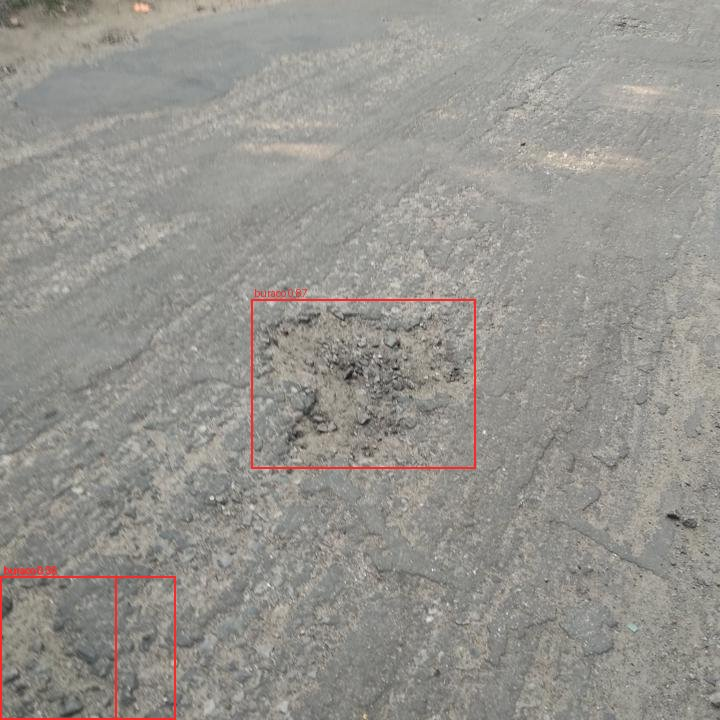

In [6]:
def detectar(nome, dados_jpeg):
    r = requests.post(f"{API}/detectar", files={"imagem": (nome, dados_jpeg, "image/jpeg")})
    r.raise_for_status(); resp = r.json()
    print({k: v for k, v in resp.items() if k != "imagem_anotada_base64"})
    return Image.open(io.BytesIO(base64.b64decode(resp["imagem_anotada_base64"])))

# 1) imagem do conjunto de teste (Pothole Dataset, ODbL v1.0)
foto = sorted(Path("../dados/zelacidade/images/test").glob("*"))[0]
detectar(foto.name, foto.read_bytes())

{'detectado': True, 'n_buracos': 2, 'severidade': 'media', 'categoria_sugerida': 'buraco_via', 'deteccoes': [{'classe': 'buraco', 'confianca': 0.7782, 'bbox_xyxy': [488.5, 215.4, 650.6, 302.3], 'area_relativa': 0.0153}, {'classe': 'buraco', 'confianca': 0.4829, 'bbox_xyxy': [0.8, 212.2, 81.7, 276.4], 'area_relativa': 0.0056}], 'modelo': 'buraco.pt', 'latencia_ms': 15.9, 'aviso': 'Sugestão automática: confirme a categoria antes de registrar.'}


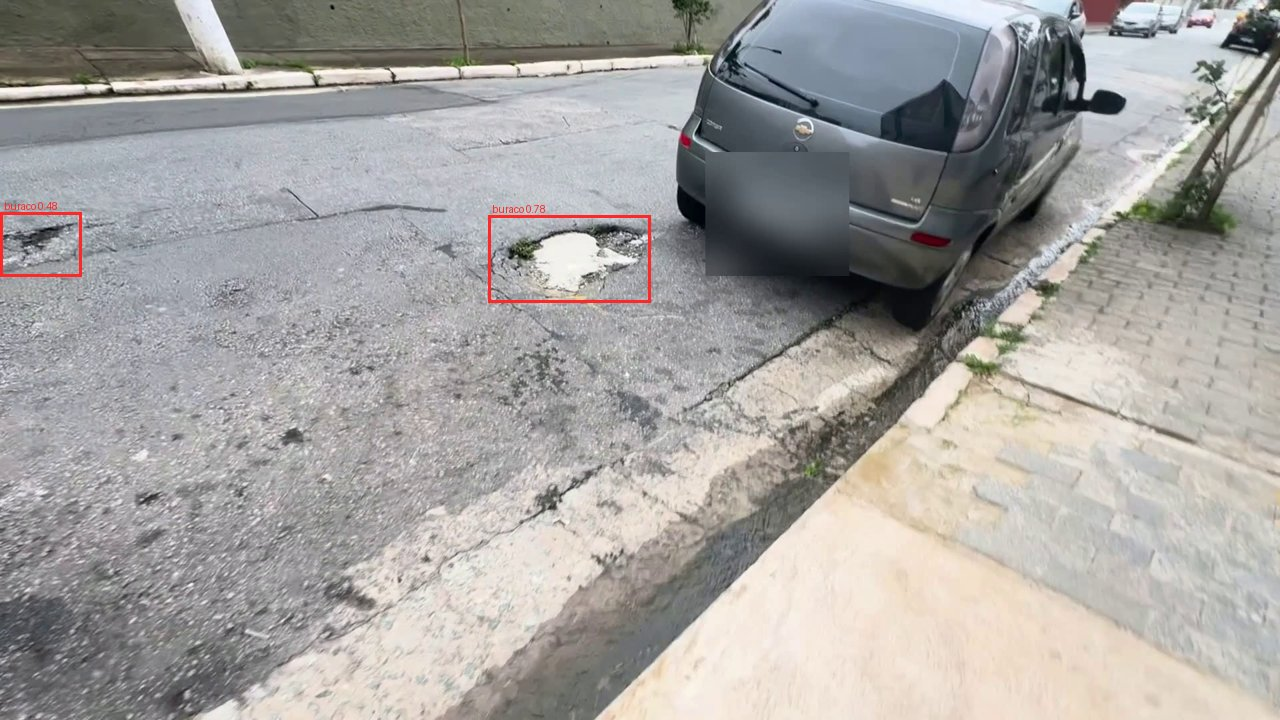

In [7]:
# 2) quadro CRU do nosso vídeo (sem anotação), como se fosse a foto enviada pelo morador
cap = cv2.VideoCapture("../videos/rua.mp4"); cap.set(cv2.CAP_PROP_POS_FRAMES, 228); ok, quadro = cap.read(); cap.release()
detectar("quadro_228.jpg", cv2.imencode(".jpg", quadro)[1].tobytes())